# Inspection of The Results

After all the experiments were ran, it is time to inspect and analyze the outcome. There will be the following parts to that:
1. General inspection of constraint properties, excluding coverage and regularity. The subjects of the inspection will be the distributions of the constraints by 1) the type of linguistic information they employ; 2) their target item.
2. General inspection of the coverage and regularity measures. At this step, the obtained values will be inspected, which includes the analysis of their distribution and correlation.
3. Inspection of item against type regularity values. This inspection gives an idea about the presence of negative outliers within covered items of the constraints.
4. Inspection of the extent to which the claims about the constraints made in the literature are supported by the data. That includes comparison of the quantifiers specified in the constraint definitions ("regularly", "mostly" etc.) and the obtained item regularity values. We concentrate on the item variant since we want a more balanced estimation not affected by productive outliers.
5. Inspection of the extent to which our suggestions to the definitions of not fully supported constraints are supported by the data.

In [1]:
# project-level pwd
%cd ..

/Users/maxschmaltz/Documents/DieKonstraintsPrivat/semrel_comp_corp_study-private


In [3]:
import os
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
# from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import statsmodels.formula.api as smf
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.markers import MarkerStyle
from collections import Counter, defaultdict
from itertools import product, pairwise
import yaml
from typing import List, Tuple

from data_utils import load_datasets
from check_applicability.regularity_scale import REGULARITY_SCALE

## 1. General Inspection of Constraint Properties

Our goal for this step of inspection is to retrieve the following:
1. The distribution of the constraints by the type of linguistic information they employ.
2. The distribution of the constraints by their target items.

Both properties are retrievable directly from the [master constraints file](../constraints/constraints_all_revised.yaml) so we load and access it here.

In [4]:
constr_path = "constraints/constraints_all_revised.yaml"

appl_stat_dir = "out/constraints/applicability_statistics"
constr_stat_dir = "out/constraints/constraint_statistics/"

# os.makedirs(appl_stat_dir, exist_ok=True)
os.makedirs(constr_stat_dir, exist_ok=True)

In [5]:
save_tsv = lambda df, path: df.to_csv(
    path,
    sep="\t",
    header=True,
    index=True
)

save_cstat_tsv = lambda df, name: save_tsv(
    df,
    os.path.join(constr_stat_dir, f"{name}.tsv")
)

save_astat_tsv = lambda df, name: save_tsv(
    df,
    os.path.join(appl_stat_dir, f"{name}.tsv")
)

In [6]:
# load constraints and dataset specs
with open(constr_path, encoding="utf-8") as f:
    yamls = list(yaml.safe_load_all(f))
    constraints: dict = yamls[-1]["constraints"]
    data_specs: dict = yamls[-2]["datasets"]

# load datasets
datasets = {
    dname: getattr(load_datasets, d["load_func"])(d["filepath"])
    for dname, d in data_specs.items()
}

### 1.1. Distribution of Constraints by Linguistic Information Type

Beside the linguistic info type, we will also distinguish between the application type (P2l/L2P).

In [7]:
ling_type_data = {
    "p2l": defaultdict(int),
    "l2p": defaultdict(int)
}

for c_id, constraint in constraints.items():
    if c_id == "def-0": # disregard the default constraint
        continue
    ling_type = sorted(constraint["ling_info_type"])    # sort for multiple types
    ling_type_str = "+".join(ling_type)
    appl_type = c_id.split(":")[0]
    ling_type_data[appl_type][ling_type_str] += 1

ling_types = pd.DataFrame(
    data=ling_type_data
).fillna(0).astype(int).sort_index()

save_cstat_tsv(ling_types, "ling_types")
ling_types

,p2l,l2p
derivational,9,2
derivational+morphological,1,1
derivational+morphological+phonological,1,0
derivational+phonological,0,3
derivational+semantic,2,0
lexical,1,4
lexical+morphological,0,1
lexical+morphological+phonological+semantic,0,1
lexical+semantic,1,0
morphological,6,6


In [8]:
ling_types["p2l"].sum().item(), ling_types["l2p"].sum().item()

(41, 22)

In [9]:
domains = ["morphological", "derivational", "phonological", "semantic", "lexical"]

domain_df = pd.Series(
	index=domains,
	data=
	{
		t: ling_types[
			ling_types.index.str.contains(t)
		].sum().sum().item()
		for t in domains
	}
)

save_cstat_tsv(domain_df, "involved_domains")
domain_df

morphological    33
derivational     19
phonological     18
semantic         19
lexical           8
dtype: int64

### 1.2. Distribution of Constraints by Target Item

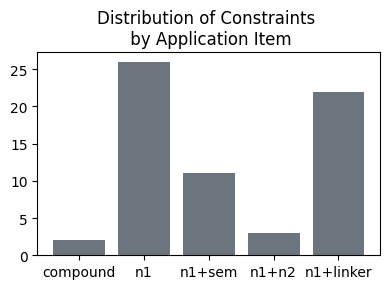

In [10]:
appl_items = [c["appl_item"] for c in constraints.values()]
counts = Counter(appl_items)
keys, values = counts.keys(), counts.values()

plt.figure(figsize=(4, 3))

bars = plt.bar(keys, values, color="#6c757d")

plt.title("Distribution of Constraints \n by Application Item")

plt.tight_layout()
plt.savefig(
    os.path.join(constr_stat_dir, "appl_item_distr.png"),
    dpi="figure"
)
plt.show()

Additionally, we want to know which number of possible items each type has. For that, we need to access GeCoDB_v06.

In [11]:
appl_item_counts_data = defaultdict(dict)

# TODO: optimize
for c_id, dname in product(constraints, data_specs):
    constr = constraints[c_id]
    if dname not in constr["datasets_n_appl_items"]:
        continue
    appl_item_counts_data[constr["appl_item"]][dname] = constr["datasets_n_appl_items"][dname]

appl_item_counts = pd.DataFrame(appl_item_counts_data)

save_cstat_tsv(appl_item_counts, "appl_item_counts")
appl_item_counts

,compound,n1,n1+sem,n1+linker
gecodb_v06,282767.0,3614.0,NaN,4870
gecodb_v07,275409.0,3594.0,NaN,4743
sp18_pl_constr,NaN,NaN,78.0,88


## 2. General Inspection of The Coverage and Regularity Measures

Here, we load the general applicability statistics table and retrieve three things:
1. Scatter plots of coverage against regularity in two variants each (item, type).
    * A shared plot.
    * P2L vs L2P.
2. Central tendency measures of the distributions (shared, P2L, L2P).
3. Qualitative analysis of the values clusters.

### 2.1. Draw Scatter Plot

In [12]:
stats = pd.read_csv(
    os.path.join(appl_stat_dir, "appl_statistics_summary.tsv"),
    sep="\t",
    index_col=(0, 1),
    header=0
).dropna()  # remove non-implemented constraints

stats

appl_item  n_appl_items  \
constr_id                 dataset                                   
def-0                     gecodb_v06       compound      282767.0   
                          gecodb_v07       compound      275409.0   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06             n1        3614.0   
                          gecodb_v07             n1        3594.0   
p2l:decl_cl:pl:#s-0       gecodb_v06             n1        3614.0   
...                                             ...           ...   
l2p:es|mono_syl           gecodb_v06      n1+linker        4870.0   
                          gecodb_v07      n1+linker        4743.0   
l2p:0_uml                 gecodb_v06      n1+linker        4870.0   
                          gecodb_v07      n1+linker        4743.0   
l2p:pl_marker|def-pl      sp18_pl_constr  n1+linker          88.0   

                                                quantifier  cvg_item_abs  \
constr_id                 dataset                                          
def-0                     gecodb_v06              majority      282767.0   
                          gecodb_v07              majority      275409.0   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06      almost regularly         241.0   
                          gecodb_v07      almost regularly         240.0   
p2l:decl_cl:pl:#s-0       gecodb_v06            almost all         128.0   
...                                                    ...           ...   
l2p:es|mono_syl           gecodb_v06                   all          58.0   
                          gecodb_v07                   all          54.0   
l2p:0_uml                 gecodb_v06                   all          17.0   
                          gecodb_v07                   all          15.0   
l2p:pl_marker|def-pl      sp18_pl_constr              tend          40.0   

                                          cvg_item  cvg_type  reg_item  \
constr_id                 dataset                                        
def-0                     gecodb_v06         1.000     1.000     0.578   
                          gecodb_v07         1.000     1.000     0.577   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06         0.067     0.066     0.954   
                          gecodb_v07         0.067     0.065     0.958   
p2l:decl_cl:pl:#s-0       gecodb_v06         0.035     0.033     0.970   
...                                            ...       ...       ...   
l2p:es|mono_syl           gecodb_v06         0.012     0.011     0.983   
                          gecodb_v07         0.011     0.011     0.963   
l2p:0_uml                 gecodb_v06         0.003     0.000     1.000   
                          gecodb_v07         0.003     0.000     1.000   
l2p:pl_marker|def-pl      sp18_pl_constr     0.455     0.465     0.146   

                                          reg_type  n_violations  \
constr_id                 dataset                                  
def-0                     gecodb_v06         0.578    119391.000   
                          gecodb_v07         0.577    116594.000   
p2l:decl_cl:pl:#0-0|def-0 gecodb_v06         0.936        11.047   
                          gecodb_v07         0.939        10.051   
p2l:decl_cl:pl:#s-0       gecodb_v06         0.957         3.893   
...                                            ...           ...   
l2p:es|mono_syl           gecodb_v06         0.940         1.000   
                          gecodb_v07         0.939         2.000   
l2p:0_uml                 gecodb_v06         1.000         0.000   
                          gecodb_v07         1.000         0.000   
l2p:pl_marker|def-pl      sp18_pl_constr     0.153        34.159   

                                         is_productive is_regular  \
constr_id                 dataset                                   
def-0                     gecodb_v06             False      False   
                          gecodb_v07             False      False   
p2l:decl_cl:pl:#0-0|def-0 gecod

In [13]:
stat_ids = np.unique([ind[0] for ind in stats.index])
len(stat_ids)

48

In [14]:
np.char.startswith(stat_ids, "p2l:").sum().item(), np.char.startswith(stat_ids, "l2p:").sum().item()

(31, 16)

In [15]:
stats = stats.swaplevel(0, 1)

Now draw the plots. We start with the shared plot.

In [16]:
dot_kw = {
    "facecolors": "none",   # hollow inside
    "edgecolors": "black",  # outline
    "s": 100                 # marker size
}

line_kw = {
    "color": "black",
    "linewidth": 0.5,
    "linestyle": "--",
    "alpha": 0.6
}

line_label_kw = {
    "fontsize": 7,
    "alpha": 0.8,
    "clip_on": False
}

# https://matplotlib.org/stable/api/markers_api.html#module-matplotlib.markers
markers = {
    # add with new datasets
    "gecodb_v06": "o",
    "gecodb_v07": "v",
    "sp18_pl_constr": "p",
    # "*",
    # "s"
}

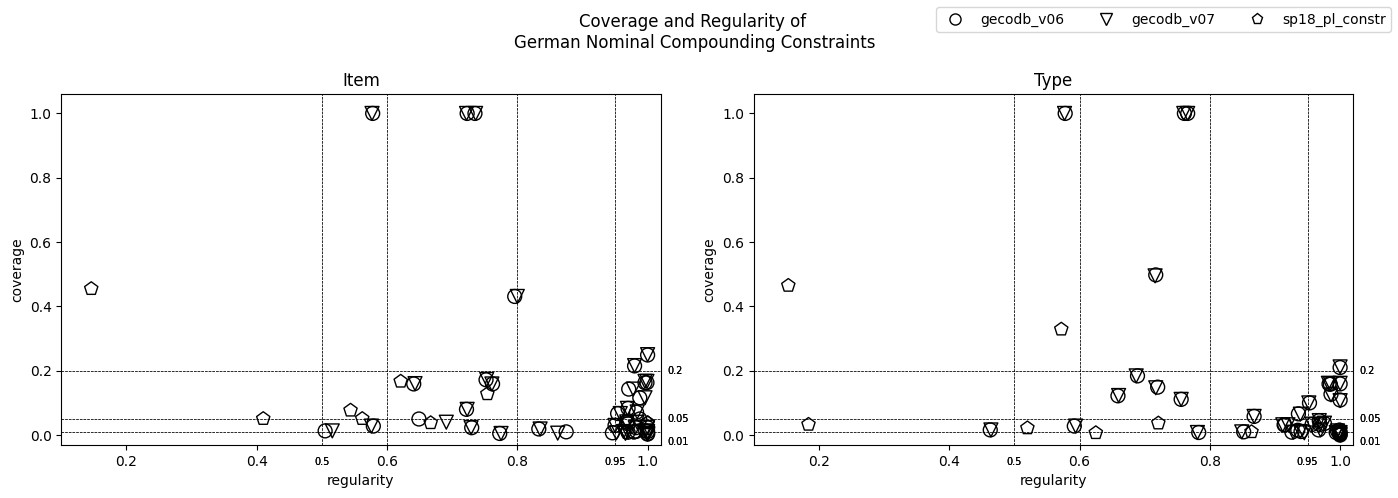

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

legend = []
for dname in data_specs:

    stats_dname = stats.loc[dname]
    marker = markers[dname]

    # item cvg/reg values
    axes[0].scatter(
        stats_dname["reg_item"],
        stats_dname["cvg_item"],
        **dot_kw,
        marker=marker
    )
    axes[0].set_xlabel("regularity")
    axes[0].set_ylabel("coverage")
    axes[0].set_title("Item")


    # type cvg/reg values
    axes[1].scatter(
        stats_dname["reg_type"],
        stats_dname["cvg_type"],
        **dot_kw,
        marker=marker
    )
    axes[1].set_xlabel("regularity")
    axes[1].set_ylabel("coverage")
    axes[1].set_title("Type")

    for ax in axes:

        ax.set_xlim(0.1, 1.02)
        ax.set_ylim(-0.03, 1.06)

        # horizontal lines for coverage
        for y in [0.01, 0.05, 0.2]:
            ax.axhline(y=y, **line_kw)
            ax.text(
                1.03, y - (0.03 * (y == 0.01)), y,
                va="center", ha="left", **line_label_kw
            )

        # vertical lines for regularity
        for x in [0.5, 0.6, 0.8, 0.95]:
            ax.axvline(x=x, **line_kw)
            if not x in ax.get_xticks().round(2):
                ax.text(
                    x, -0.1, x,
                    va="bottom", ha="center",
                    **line_label_kw
                )

    legend_handle = mlines.Line2D(
        [], [], color="black", marker=marker, linestyle="None",
        markersize=8, markerfacecolor="none", label=dname
    )
    legend.append(legend_handle)

fig.suptitle(
    "Coverage and Regularity of \n"
    "German Nominal Compounding Constraints"
)
fig.legend(handles=legend, loc="upper right", ncol=len(legend))

plt.tight_layout()
plt.savefig(
    os.path.join(appl_stat_dir, "cvg_reg.png"),
    dpi="figure"
)
plt.show()

In [18]:
r = lambda x, y: x.corr(y, method="pearson")

mw_gecodb_v06_vs_gecodb_v07_data = {}
for param in [("reg", "item"), ("reg", "type"), ("cvg", "item"), ("cvg", "type")]:
    param_str = "_".join(param)
    mw = mannwhitneyu(stats.loc["gecodb_v06", param_str], stats.loc["gecodb_v07", param_str])
    mw_gecodb_v06_vs_gecodb_v07_data[param] = {
        "U": mw.statistic,
        "p": mw.pvalue,
        "r": r(stats.loc["gecodb_v06", param_str], (stats.loc["gecodb_v07", param_str]))
    }

mw_gecodb_v06_vs_gecodb_v07 = pd.DataFrame(mw_gecodb_v06_vs_gecodb_v07_data).round(3)

save_astat_tsv(mw_gecodb_v06_vs_gecodb_v07, "mw_gecodb_v06_vs_gecodb_v07")
mw_gecodb_v06_vs_gecodb_v07

reg              cvg         
      item     type    item     type
U  783.000  761.500  771.00  781.000
p    0.826    0.996    0.92    0.841
r    0.998    1.000    1.00    1.000

=> we can use either

In [19]:
set(stats.loc["gecodb_v07"].index) & set(stats.loc["sp18_pl_constr"].index)

set()

In [20]:
stats_flat = stats.loc[["gecodb_v07", "sp18_pl_constr"]]    \
    .reset_index(level=0, drop=False)
stats_flat

,dataset,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,,
def-0,gecodb_v07,compound,275409.0,majority,275409.0,1.000,1.000,0.577,0.577,116594.000,False,False,low regularity,low regularity,supported
p2l:decl_cl:pl:#0-0|def-0,gecodb_v07,n1,3594.0,almost regularly,240.0,0.067,0.065,0.958,0.939,10.051,True,False,high regularity,high regularity,supported
p2l:decl_cl:pl:#s-0,gecodb_v07,n1,3594.0,almost all,126.0,0.035,0.034,0.968,0.957,3.977,True,True,high regularity,regular,supported+
p2l:decl_cl:pl:#e-0|def-0,gecodb_v07,n1,3594.0,mostly,570.0,0.159,0.184,0.761,0.687,136.140,False,False,low regularity,moderate regularity,supported+
p2l:decl_cl:pl:#er-0/er|def-0/er,gecodb_v07,n1,3594.0,mostly,70.0,0.019,0.058,0.835,0.868,11.557,True,False,low regularity,moderate regularity,supported+
p2l:decl_cl:pl:#e_uml-0|def-0,gecodb_v07,n1,3594.0,mostly,287.0,0.080,0.111,0.723,0.756,79.519,False,False,low regularity,moderate regularity,supported+
p2l:decl_cl:pl:#0_uml-0|def-0,gecodb_v07,n1,3594.0,almost always,25.0,0.007,0.016,0.952,0.970,1.190,True,True,high regularity,regular,supported+
p2l:decl_cl:mixed-0/s/en|def-0/s/en,gecodb_v07,n1,3594.0,regularly,46.0,0.013,0.013,0.996,0.996,0.163,True,True,regular,regular,supported
p2l:drv:sfx:0_pl_sfx-0,gecodb_v07,n1,3594.0,regularly,257.0,0.072,0.045,0.984,0.968,4.069,True,True,regular,regular,supported


In [21]:
stats_flat_p2l = stats_flat[stats_flat.index.str.startswith("p2l:")]
stats_flat_l2p = stats_flat[stats_flat.index.str.startswith("l2p:")]

In [22]:
item_type_desc_data = {}
for param in [("reg", "item"), ("reg", "type"), ("cvg", "item"), ("cvg", "type")]:
    param_str = "_".join(param)
    item_type_desc_data[param] = stats_flat[param_str] \
        .describe(percentiles=[0.5, 0.9])

item_type_desc = pd.concat(item_type_desc_data, axis=1).T.round(3)
save_astat_tsv(item_type_desc, "item_type_desc")
item_type_desc

count   mean    std    min    50%    90%  max
reg item   48.0  0.832  0.197  0.146  0.955  1.000  1.0
    type   48.0  0.836  0.209  0.153  0.939  1.000  1.0
cvg item   48.0  0.140  0.245  0.003  0.040  0.304  1.0
    type   48.0  0.135  0.251  0.000  0.033  0.370  1.0

In [23]:
mw_item_type = pd.DataFrame({
   param: {
        "U": (mw := mannwhitneyu(stats_flat[f"{param}_item"], stats_flat[f"{param}_type"])).statistic,
        "p": mw.pvalue,
        "r": r(stats_flat[f"{param}_item"], stats_flat[f"{param}_type"]),
        "mae": mean_absolute_error(stats_flat[f"{param}_item"], stats_flat[f"{param}_type"])
    }
    for param in ["cvg", "reg"]
}).round(3)

save_astat_tsv(mw_item_type, "mw_item_type")
mw_item_type

,cvg,reg
U,1280.00,1119.000
p,0.35,0.811
r,0.99,0.930
mae,0.02,0.043


In [24]:
def get_cvg_reg_clusters_legacy(stats: pd.DataFrame) -> dict:
    return {
        ("cvg_comb", ">= 0.2"): stats[
            (stats["cvg_item"] >= 0.2) & (stats["cvg_type"] >= 0.2)
        ].shape[0],
        ("cvg_comb", "< 0.2"): stats[
            (stats["cvg_item"] < 0.2) & (stats["cvg_type"] < 0.2)
        ].shape[0],
        ("cvg_comb", "< 0.05"): stats[
            (stats["cvg_item"] < 0.05) & (stats["cvg_type"] < 0.05)
        ].shape[0],
        ("reg_comb", "<= 0.9"): stats[
            (stats["reg_item"] <= 0.9) & (stats["reg_type"] <= 0.9)
        ].shape[0],
        ("reg_comb", "> 0.9"): stats[
            (stats["reg_item"] > 0.9) & (stats["reg_type"] > 0.9)
        ].shape[0],
        ("reg_comb", "> 0.98*"): stats[
            (
                (stats["reg_item"] > 0.98) |
                (
                    (stats["cvg_item"] <= 0.01)
                    & (stats["reg_item"] > 0.97)
                )
            ) & 
            (stats["reg_type"] > 0.98)
        ].shape[0]
    }

cvg_reg_clusters_legacy = pd.DataFrame(
    {
        "all": get_cvg_reg_clusters_legacy(stats_flat),
        "P2L": get_cvg_reg_clusters_legacy(stats_flat_p2l),
        "L2P": get_cvg_reg_clusters_legacy(stats_flat_l2p)
    }
)

save_astat_tsv(cvg_reg_clusters_legacy, "cvg_reg_clusters_legacy")
cvg_reg_clusters_legacy

all  P2L  L2P
cvg_comb >= 0.2     6    4    1
         < 0.2     40   25   15
         < 0.05    24   13   11
reg_comb <= 0.9    19   16    2
         > 0.9     25   13   12
         > 0.98*   12    5    7

=> we can use either

In [25]:
get_reg_clusters = lambda stats, cp: pd.Series({
	f"{left}-{right}": (
		(stats["reg_item"] >= left) &
		(stats["reg_item"] < right)
	).sum()
	for left, right in pairwise(cp)
})

critical_points = [0.5, 0.6, 0.8, 0.95, 1.01]
reg_clusters = pd.DataFrame(
    {
        "all": get_reg_clusters(stats_flat, critical_points),
        "P2L": get_reg_clusters(stats_flat_p2l, critical_points),
        "L2P": get_reg_clusters(stats_flat_l2p, critical_points)
    }
)

reg_clusters

,all,P2L,L2P
0.5-0.6,5,4,0
0.6-0.8,12,10,2
0.8-0.95,3,2,1
0.95-1.01,26,14,12


In [26]:
critical_points.remove(0.8)
reg_clusters = pd.DataFrame(
    {
        "all": get_reg_clusters(stats_flat, critical_points),
        "P2L": get_reg_clusters(stats_flat_p2l, critical_points),
        "L2P": get_reg_clusters(stats_flat_l2p, critical_points)
    }
)

save_astat_tsv(reg_clusters, "reg_clusters")
reg_clusters

,all,P2L,L2P
0.5-0.6,5,4,0
0.6-0.95,15,12,3
0.95-1.01,26,14,12


In [27]:
mw_p2l_l2p_data = {}
for sign, a in [("=", "two-sided"), (">", "greater"), ("<", "less")]:
    res = pd.DataFrame({
        param: {
            f"U": (mw := mannwhitneyu(stats_flat_p2l[f"{param}_item"], stats_flat_l2p[f"{param}_type"], alternative=a)).statistic,
            f"p": mw.pvalue
        }
        for param in ["cvg", "reg"]
    })
    mw_p2l_l2p_data[f"P2L{sign}L2P"] = res
mw_p2l_l2p = pd.concat(mw_p2l_l2p_data, names=["alternative"]).round(3)

save_astat_tsv(mw_p2l_l2p, "mw_p2l_l2p")
mw_p2l_l2p

cvg      reg
alternative                    
P2L=L2P     U  338.500  137.000
            p    0.043    0.013
P2L>L2P     U  338.500  137.000
            p    0.022    0.994
P2L<L2P     U  338.500  137.000
            p    0.980    0.006

In [28]:
corr_cvg_reg = pd.DataFrame({
    "r": {
        v: stats_flat[f"reg_{v}"].corr(stats_flat[f"cvg_{v}"], method="pearson")
        for v in ["item", "type"]
    }
}).T.round(3)

save_astat_tsv(corr_cvg_reg, "corr_cvg_reg")
corr_cvg_reg

,item,type
r,-0.321,-0.32


In [29]:
ling_type_mtrx = stats_flat.apply(
    lambda row: {
        ling_type: True
        for ling_type in constraints[row.name]["ling_info_type"]
    },
    axis=1,
    result_type="expand"
)
ling_type_mtrx.fillna(False, inplace=True)
# too few representatives
ling_type_mtrx.drop(columns=["default", "lexical"], inplace=True)

In [30]:
cols = ["morphological", "derivational", "phonological", "semantic"]
stats_flat = pd.concat((stats_flat, ling_type_mtrx), axis=1)
stats_flat.drop(
    # the default and one lexical constraint
    stats_flat[stats_flat.apply(
        lambda row: row[cols].sum() == 0,
        axis=1
    )].index,
    inplace=True
)
stats_flat.sample(5)

,dataset,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level,morphological,derivational,phonological,semantic
constr_id,,,,,,,,,,,,,,,,,,,
p2l:phon_fin:weak_F_cons$-0/s/en|!pl_interpr-0/s,sp18_pl_constr,n1+sem,78.0,mostly,4.0,0.051,0.033,0.410,0.184,2.359,True,False,low regularity,below scale,not supported,True,False,True,True
l2p:s|f_cmpx,gecodb_v07,n1+linker,4743.0,almost all,794.0,0.167,0.161,0.996,0.982,3.000,True,True,high regularity,regular,supported+,True,True,False,False
p2l:drv:prx_deverb-s,gecodb_v07,n1,3594.0,tendency,574.0,0.160,0.123,0.643,0.660,204.992,False,False,moderate regularity,moderate regularity,supported,False,True,False,False
p2l:phon_fin:weak_F_cons$-0/s/en|def-0/s/en,gecodb_v07,n1,3594.0,regularly,899.0,0.250,0.212,1.000,1.000,0.000,True,True,regular,regular,supported,True,False,True,False
p2l:tend:cmpx_phon-s|def-s,gecodb_v07,n1,3594.0,tendency,3594.0,1.000,1.000,0.722,0.760,997.373,False,False,moderate regularity,moderate regularity,supported,False,False,True,False


In [31]:
# https://matplotlib.org/stable/gallery/color/named_colors.html
colors = {
    "morphological": "red",
    "derivational": "green",
    "phonological": "blue",
    "semantic": "gold",
    "lexical": "blueviolet"
}
matplotlib.rcParams["hatch.linewidth"] = 2.0

def get_dots(ling_types: List[str], marker: str) -> dict:
    ling_types = sorted(ling_types)
    match len(ling_types):
        case 1:
            dots = [{
                "facecolors": colors[ling_types[0]],
                
                "marker": marker
            }]
        case 2:
            # two halves
            dots = [
                {
                    "facecolors": colors[ling_types[0]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="left"
                    )
                },
                {
                    "facecolors": colors[ling_types[1]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="right"
                    )
                }
            ]
        case 3:
            # two halves + hatch
            dots = [
                {
                    "facecolors": colors[ling_types[0]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="left"
                    )
                },
                {
                    "facecolors": colors[ling_types[1]],
                    "edgecolors": "none",
                    "marker": MarkerStyle(
                        marker=marker,
                        fillstyle="right"
                    )
                },
                {
                    "facecolors": "none",
                    "edgecolors": colors[ling_types[2]],
                    "hatch": "////",
                    "marker": marker
                }
            ]
        case _:
            raise NotImplemented
    return dots    

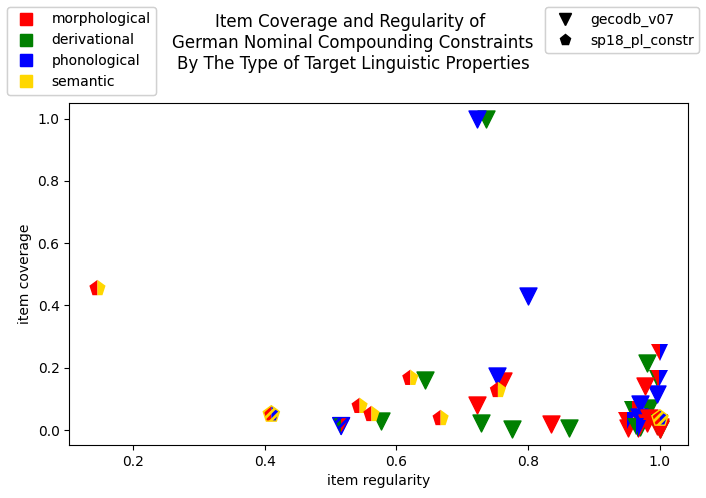

In [32]:
fig, axis = plt.subplots(1, 1, figsize=(7, 5))

for c_id, row in stats_flat.iterrows():

    if c_id == "def-0":
        continue

    marker = markers[row["dataset"]]
    dots = get_dots(constraints[c_id]["ling_info_type"], marker)
    for dot in dots:
        axis.scatter(
            row["reg_item"],
            row["cvg_item"],
            s=150,
            **dot
        )

axis.set_xlabel("item regularity")
axis.set_ylabel("item coverage")

legend_dataset = [
    mlines.Line2D(
        [], [], color="black", marker=markers[dname], linestyle="None",
        markersize=8, markerfacecolor="black", label=dname
    )
    for dname in stats_flat["dataset"].unique()
]
legend_colors = [
    mlines.Line2D(
        [], [], color=color, marker="s", linestyle="None",
        markersize=8, markerfacecolor=color, label=ling_type
    )
    for ling_type, color in colors.items()
    if ling_type in stats_flat
]

fig.suptitle(
    "Item Coverage and Regularity of \n"
    "German Nominal Compounding Constraints\n"
    "By The Type of Target Linguistic Properties"
)
legc = fig.legend(handles=legend_colors, loc="upper left")
legd = fig.legend(handles=legend_dataset, loc="upper right")
axis.add_artist(legc)
axis.add_artist(legd)

plt.tight_layout()
plt.subplots_adjust(top=0.8)
plt.savefig(
    os.path.join(appl_stat_dir, "cvg_reg_vs_ling_type.png"),
    dpi="figure"
)
plt.show()

In [33]:
# X = stats_flat[["morphological", "derivational", "phonological", "semantic"]]
# y = {
#     "cvg": stats_flat["cvg_item"],
#     "reg": stats_flat["reg_item"]
# }

# lr_cvg_reg_vs_ling_type_data = {}
# for param in ["cvg", "reg"]:
#     lr = LinearRegression(positive=False)
#     lr.fit(X, y[param])
#     lr_cvg_reg_vs_ling_type_data[param] = {
#         "intercept": lr.intercept_,
#         **{
#             f"coef_{ling_type}": lr.coef_[i]
#             for i, ling_type in enumerate(X.columns)
#         }
#     }

# lr_cvg_reg_vs_ling_type = pd.DataFrame(lr_cvg_reg_vs_ling_type_data)
# save_astat_tsv(lr_cvg_reg_vs_ling_type, "lr_cvg_reg_vs_ling_type")
# lr_cvg_reg_vs_ling_type

In [34]:
# the same as above but more informative:
ols = smf.ols("cvg_item ~ morphological + derivational + phonological + semantic + 1", data=stats_flat).fit()
with open(os.path.join(appl_stat_dir, "lr_cvg_vs_ling_type.txt"), "w") as out:
    out.write(str(ols.summary()))
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:               cvg_item   R-squared:                       0.094
Model:                            OLS   Adj. R-squared:                  0.006
Method:                 Least Squares   F-statistic:                     1.065
Date:                Fri, 24 Jul 2026   Prob (F-statistic):              0.386
Time:                        18:27:57   Log-Likelihood:                 8.4197
No. Observations:                  46   AIC:                            -6.839
Df Residuals:                      41   BIC:                             2.304
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.25

In [35]:
ols = smf.ols("reg_item ~ morphological + derivational + phonological + semantic + 1", data=stats_flat).fit()
with open(os.path.join(appl_stat_dir, "lr_reg_vs_ling_type.txt"), "w") as out:
    out.write(str(ols.summary()))
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:               reg_item   R-squared:                       0.305
Model:                            OLS   Adj. R-squared:                  0.237
Method:                 Least Squares   F-statistic:                     4.491
Date:                Fri, 24 Jul 2026   Prob (F-statistic):            0.00422
Time:                        18:27:57   Log-Likelihood:                 18.533
No. Observations:                  46   AIC:                            -27.07
Df Residuals:                      41   BIC:                            -17.92
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.88

In [36]:
stats_flat_confirmed = stats_flat[stats_flat["reg_item"] >= 0.5]
ols = smf.ols("reg_item ~ morphological + derivational + phonological + semantic + 1", data=stats_flat_confirmed).fit()
with open(os.path.join(appl_stat_dir, "lr_reg_vs_ling_type_confirmed.txt"), "w") as out:
    out.write(str(ols.summary()))
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:               reg_item   R-squared:                       0.192
Model:                            OLS   Adj. R-squared:                  0.109
Method:                 Least Squares   F-statistic:                     2.320
Date:                Fri, 24 Jul 2026   Prob (F-statistic):             0.0739
Time:                        18:27:57   Log-Likelihood:                 24.777
No. Observations:                  44   AIC:                            -39.55
Df Residuals:                      39   BIC:                            -30.63
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.86

## 4. Inspection of The Extent to Which the Claims About the Constraints Made in The Literature Are Supported by The Data

The following steps are to be done for final inspection:
1. Manually inspect the support level of the claims in the empirical data. For each (analyzed) constraint, record the level of support. Since the definitions are mostly vague, base the decision on commonsense judgments. For the support level, we concentrate on the type variant of the measures since we focus on the linguistic side of the question (not real usage). There are 4 levels of support:
    * Supported. Full or very close correspondence between the quantifier and the empirical data. Examples: "regular" vs 0.99, "mostly" vs 0.75.
    * Partially supported. The gap is not critical yet noticeable. Examples: "regular" vs 0.93, "tends" vs 0.6, "sometimes" vs 0.9.
    * Not supported. The discrepancy between the quantifier and the empirical data is too significant to ignore. Examples: "regular" vs 0.85, "tends" vs 0.4.
    * NA: no data available (unreliable or semantic/lexical constraints).

Note: this steps is being conducted in the file with constraints definitions, see `constraints/constraints.yaml`. While it is being now made at the time of this inspection, we cannot reflect this processes here. After this step is done, we pull the results from this file and further inspect them in detail, specifically:

2. Inspect the distribution of the support levels.
3. Manually inspect the constraints that are only partially supported by the data or not supported at all.

### 4.1. Inspection of The Support Level

Done separately in `constraints/constraints.yaml`.

NEW SCALE:

0.5, 0.6, 0.8, 0.95 | regular

In [104]:
# # Yang 2016: 67
# 23 is an error in the original table,
# see Yang 2016: 62
# 100 / ln(100) ~= 21.715
yang_values = [10, 20, 50, 100, 200, 500, 1000, 5000]
irreg_tp_values_data = {
    "TP": {
        n: REGULARITY_SCALE._yang_theta(n)
        for n in yang_values
    },
    "ITP": {
        n: 1 - REGULARITY_SCALE._irreg_tolerance(n)
        for n in yang_values
    }
}
irreg_tp_values = pd.DataFrame(irreg_tp_values_data)
irreg_tp_values["TP"] = irreg_tp_values["TP"].astype(int)
irreg_tp_values["ITP"] = irreg_tp_values["ITP"].round(3)
save_astat_tsv(irreg_tp_values, "irreg_tp_values")
irreg_tp_values

,TP,ITP
10,4,0.770
20,6,0.850
50,12,0.922
100,21,0.954
200,37,0.974
500,80,0.988
1000,144,0.993
5000,587,0.998


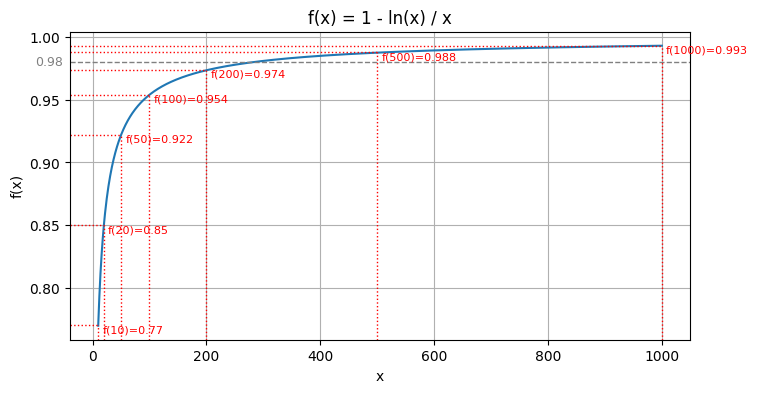

In [103]:
x = np.arange(10, 1001)
y = 1 - np.log(x) / x

fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.plot(x, y)

# draw the old threshold
for x in [0.98]:
    ax.axhline(y=x, color="grey", linestyle="--", linewidth=1)
    ax.text(
        -100, x, x,
        va="center", ha="left", color="grey", fontsize=9
    )

# draw new threshold examples
for x, y in irreg_tp_values["ITP"].items():
    if x > 1000:
        continue
    x_max, y_max = ax.transAxes.inverted().transform(ax.transData.transform((x, y)))
    ax.axvline(x=x, ymax=y_max, color="red", linewidth=1, linestyle=":")
    ax.axhline(y=y, xmax=x_max, color="red", linewidth=1, linestyle=":")
    ax.text(x + 7.5, y - 0.0075, f"f({x})={y}", color="red", fontsize=8, va="bottom", ha="left")

plt.xlabel("x")
plt.ylabel("f(x)")

plt.title("f(x) = 1 - ln(x) / x")
plt.grid(True)
plt.savefig(
    os.path.join(appl_stat_dir, "irreg_threshold.png"),
    dpi="figure"
)
plt.show()

### 4.2. Inspection of Support Level Distribution

Now, we read the constraint definition file for inspection.

In [55]:
support_levels = pd.DataFrame({
    dname: {
        sl: (stats.loc[dname]["support_level"] == sl).sum()
        for sl in stats["support_level"].unique()
    }
    for dname in data_specs
})

save_astat_tsv(support_levels, "support_levels")
support_levels

,gecodb_v06,gecodb_v07,sp18_pl_constr
supported,25,26,3
supported+,12,12,4
partially supported,2,1,0
not supported,0,0,2


In [ ]:
constrs_by_itp = stats_flat.groupby(["is_productive", "is_regular"]).size()
save_astat_tsv(constrs_by_itp, "constrs_by_itp")
constrs_by_itp

is_productive  is_regular
False          False         11
True           False         13
               True          22
dtype: int64

In [101]:
unprod_constr = stats_flat[~stats_flat["is_productive"].astype(bool)]	\
	[["cvg_item_abs", "n_violations", "reg_item", "actual_reg_level"]]

unprod_constr.insert(
	1, "n_violations_allowed",
	unprod_constr["cvg_item_abs"].map(
		REGULARITY_SCALE._yang_theta
	).round(3)
)

save_astat_tsv(unprod_constr, "unprod_constr")
unprod_constr

,cvg_item_abs,n_violations_allowed,n_violations,reg_item,actual_reg_level
constr_id,,,,,
p2l:decl_cl:pl:#e-0|def-0,570.0,89.826,136.140,0.761,moderate regularity
p2l:decl_cl:pl:#e_uml-0|def-0,287.0,50.711,79.519,0.723,moderate regularity
p2l:drv:deverb_schwa$-0|def-0,100.0,21.715,42.448,0.576,low regularity
p2l:drv:prx_deverb-s,574.0,90.356,204.992,0.643,moderate regularity
p2l:phon_fin:F_stem_#t$-s,46.0,12.015,22.242,0.516,low regularity
p2l:phon_fin:schwa$-en|def-en,620.0,96.427,152.943,0.753,moderate regularity
p2l:tend:cmpx_morph-s|def-s,3594.0,438.988,947.188,0.736,moderate regularity
p2l:tend:cmpx_phon-s|def-s,3594.0,438.988,997.373,0.722,moderate regularity
p2l:tend:sonority-!s,1549.0,210.881,310.151,0.800,moderate regularity


### 4.3. Qualitative Inspection of Partially / Not Supported Constraints

Partially supported constraints.

In [51]:
def load_appl_index(dname):
    return pd.read_csv(
        os.path.join(appl_stat_dir, dname, "appl_index.tsv"),
        sep="\t",
        header=0,
        index_col="comp_gecodb",
        dtype=defaultdict(
            # to be able to parse NAs in boolean columns
            lambda: "boolean[pyarrow]",
            comp_gecodb=str,
            **{
                f"{c_id}_item": str
                for c_id in constraints
            }
        )
    )

def inspect_constr_appl(
    appl_index: pd.DataFrame, c_id: str,  only_violations: bool=True
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    # subsample the dataset stats
    sample = appl_index[
        # only covered compounds
        appl_index[c_id + "_is_applicable"]][[
        # only constraint_related columns 
        c_id + "_item", c_id + "_applies"
    ]]
    if only_violations:
        # select only violating compounds
        sample = sample[~(sample[c_id + "_applies"])].drop(columns=[c_id + "_applies"])
    items = sample[c_id + "_item"].unique()
    example_dfs = []
    for item in items:
        item_sample = sample[sample[c_id + "_item"] == item]
        Nbwi = len(item_sample)
        examples = item_sample.sample(1)
        examples["Nbwi"] = Nbwi
        example_dfs.append(examples)
    example_df = pd.concat(example_dfs, axis=0)
    example_df.sort_values(by="Nbwi", inplace=True, ascending=False)
    return sample, example_df

In [56]:
to_inspect = []
for dname, dataset in datasets.items():

	out_dir = os.path.join(appl_stat_dir, dname, "unsupported_constr")
	os.makedirs(out_dir, exist_ok=True)

	appl_index = load_appl_index(dname)

	is_unsup = stats.loc[dname, "support_level"].isin(["partially supported", "not supported"])
	unsupported_constr = stats.loc[dname].loc[is_unsup]
	save_tsv(unsupported_constr, os.path.join(out_dir, "constr_list.tsv"))

	violations = []
	for c_id in unsupported_constr.index:
		sample, examples = inspect_constr_appl(appl_index, c_id)
		sample = dataset.loc[sample.index]
		c_id_alias = constraints[c_id]["func_alias"]	# avoid "/"s in ids
		save_tsv(sample, os.path.join(out_dir, f"{c_id_alias}_sample.tsv"))
		save_tsv(examples, os.path.join(out_dir, f"{c_id_alias}_summary.tsv"))
		violations.append(examples)

	to_inspect.append((unsupported_constr, violations))

GeCoDB_v06

In [58]:
unsupported_constr, violations = to_inspect[0]
unsupported_constr

,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,
p2l:drv:sfx:sfx-s|def-s,n1,3614.0,regularly,777.0,0.215,0.158,0.980,0.985,15.267,True,False,regular,high regularity,partially supported
l2p:n,n1+linker,4870.0,all,564.0,0.116,0.109,0.988,1.000,7.000,True,False,regular,high regularity,partially supported


In [59]:
# 121 N1s, 21 N1s that build ten or more exceptions;
# cumulative number of violations 15.267 with
# the number of covered items 777, which would
# require item regularity of 0.991
violations[0]

,p2l:drv:sfx:sfx-s|def-s_item,Nbwi
comp_gecodb,,
generation_+en_ministerium,generation,89
minderheit_+en_kirche,minderheit,50
wirtschaft_datum,wirtschaft,49
spezialität_+en_brennerei,spezialität,33
süßigkeit_+en_verbot,süßigkeit,26
...,...,...
genehmigung_verfahren,genehmigung,1
kompression_strumpf,kompression,1
kleidung_stück,kleidung,1


In [60]:
# several mysanalyses (removed in GeCoDB_v07) => ignore
violations[1]

,l2p:n_item,Nbwi
comp_gecodb,,
mittel_+n_kirche,mittel+en,2
nachbar_+n_land,nachbar+en,1
zwiebel_+n_schneide,zwiebel+en,1
windel_+n_wechsel,windel+en,1
vokabel_+n_pauke,vokabel+en,1
waffel_+n_backe,waffel+en,1
semmel_+n_knödel,semmel+en,1


GeCoDB_v07

In [61]:
unsupported_constr, violations = to_inspect[1]
unsupported_constr

,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,
p2l:drv:sfx:sfx-s|def-s,n1,3594.0,regularly,777.0,0.216,0.16,0.98,0.985,15.209,True,False,regular,high regularity,partially supported


In [ ]:
# 121 N1s, 21 N1s that build ten or more exceptions;
# cumulative number of violations 15.267 with
# the number of covered items 777, which would
# require item regularity of 0.991
violations[0]

,p2l:drv:sfx:sfx-s|def-s_item,Nbwi
comp_gecodb,,
generation_+en_thema,generation,86
minderheit_+en_votum,minderheit,49
wirtschaft_gymnasium,wirtschaft,48
spezialität_+en_bier,spezialität,33
süßigkeit_+en_beutel,süßigkeit,26
...,...,...
festung_sturm,festung,1
genehmigung_verfahren,genehmigung,1
kompression_strumpf,kompression,1


SP18_Pl_Constr

In [64]:
unsupported_constr, violations = to_inspect[2]
unsupported_constr

,appl_item,n_appl_items,quantifier,cvg_item_abs,cvg_item,cvg_type,reg_item,reg_type,n_violations,is_productive,is_regular,expected_reg_level,actual_reg_level,support_level
constr_id,,,,,,,,,,,,,,
p2l:phon_fin:weak_F_cons$-0/s/en|!pl_interpr-0/s,n1+sem,78.0,mostly,4.0,0.051,0.033,0.410,0.184,2.359,True,False,low regularity,below scale,not supported
l2p:pl_marker|def-pl,n1+linker,88.0,tend,40.0,0.455,0.465,0.146,0.153,34.159,False,False,moderate regularity,below scale,not supported


In [ ]:
# only four items covered in total => further evidence required
violations[0]

,p2l:phon_fin:weak_F_cons$-0/s/en|!pl_interpr-0/s_item,Nbwi
comp_gecodb,,
person_+en_wagen,person+sgsem,44
schwester_+n_konvent,schwester+sgsem,12
nation_+en_grenze,nation+sgsem,6


In [ ]:
# productive violation
violations[1]

,l2p:pl_marker|def-pl_item,Nbwi
comp_gecodb,,
sonne_+n_gürtel,sonne+en,53
kind_+er_kurs,kind+er,53
hund_+e_kauf,hund+e,51
katze_+n_geschichte,katze+en,50
bad_+=er_kasse,"bad+""er",47
ei_+er_masse,ei+er,46
frau_+en_staffel,frau+en,45
person_+en_profil,person+en,44
weg_+e_pauschale,weg+e,44


# Appendix

Formatting the constraints file.